# From a graph to its spectrum

### Example: Three emitters in a chain and a single excitation 

- We start with one excitation in site 1
- The excitation hops along the chain $1-2-3$
- Every site can lose it by emission
- A current is produced only when it leaves site 3 into an external system. 

What is the probability that the excitation becomes current, and why? 

1. We draw the process as a graph
2. Turn the graph into a non-Hermitian matrix $H_{\rm eff}$ called effective Hamiltonian
3. Read the answer off its spectrum

## 1. From Graph to $H_{\rm eff}$

The graph has two kinds of connections, and each fills a different part of the effective Hamiltonian $H_{\rm eff}$.

| Graph | Physics | Matrix |
|---|---|---|
| site $i$, energy $\varepsilon_i$ | energy of the excitation on site $i$ | $(H_{\rm eff})_{ii}=\varepsilon_i$ |
| undirected edge $i-j$, amplitude $J_{ij}$ | coherent hopping (reversible) | $(H_{\rm eff})_{ij}=J_{ij}$ and $(H_{\rm eff})_{ji}=J_{ij}^*$ |
| arrow out of site $i$, rate $\Gamma$ | loss into a reservoir (irreversible) | add $-i\Gamma/2$ to $(H_{\rm eff})_{ii}$ |

The effective Hamiltonian can be decomposed into its Hermitian and anti-Hermitian parts: 

$$H_{\rm eff}=D+A-\tfrac{i}{2}K$$

- The site energies form the diagonal matrix $D$ and the edges form $A$. Together they are the Hermitian part $D+A$.
- The arrows out form the anti-Hermitian part $-\tfrac{i}{2}K$, where the decay matrix $K$ is Hermitian with non-negative eigenvalues. 

Here all sites have the same energy, which we take as zero, so $D=0$. 

$K$ is diagonal and holds the total rate out of each site. 

Amplitudes can be complex, and a channel shared by several sites makes $K$ non-diagonal.

The amplitudes $\psi=(\psi_1,\psi_2,\psi_3)$ start from $\psi(0)=(1,0,0)$, the excitation on site 1, and obey

$$i\,d\psi/dt=H_{\rm eff}\psi ,$$

with $\hbar=1$ and energies in units of $J$. 

- The probability to be on site $i$ is $|\psi_i|^2$
- $\|\psi\|^2$ is the probability that the excitation is still in the chain. 
- The **yield** $\phi$ is the probability that it ends up as current.

$$\phi=\Gamma_x\int_0^\infty|\psi_3(t)|^2\,dt ,$$

where $\Gamma_x$ is the extraction rate from site 3.

### Imports

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.linalg import expm, eig

Matplotlib is building the font cache; this may take a moment.


### System

In [2]:
# system parameters
eps = [0.0, 0.0, 0.0]             # site energies eps_1, eps_2, eps_3
J, gamma, Gx = 1.0, 0.1, 1.0      # hopping, emission rate of every site, extraction rate
J13 = 0.0                         # edge 1-3
start, sink = 1, 3                # initial site of the excitation, site of the extraction arrow

# function to construct the effective Hamiltonian H_eff = D + A - (i/2) K
def make_H_eff(Gx):
    D = np.diag(eps)                                                  # site energies
    A = np.array([[0, J, J13], [J, 0, J], [np.conj(J13), J, 0]])      # undirected edges, A_ji = A_ij*
    K = np.diag([gamma, gamma, gamma])                                # arrows out: emission from every site
    K[sink - 1, sink - 1] += Gx                                       # arrow out: extraction from the sink
    return D + A - 0.5j * K

# construct the effective Hamiltonian
H_eff = make_H_eff(Gx)

# compute the Hermitian and anti-Hermitian parts of H_eff
H = (H_eff + H_eff.conj().T) / 2               # Hermitian part D + A
K = 1j * (H_eff - H_eff.conj().T)              # anti-Hermitian part is -(i/2) K

### Graph

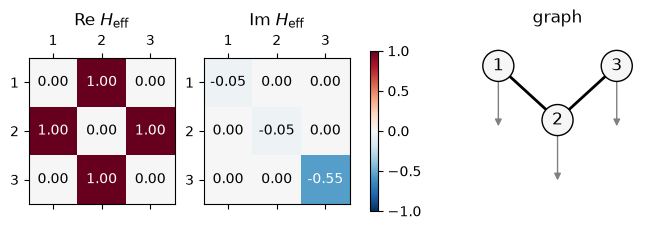

In [3]:
# H_eff is the adjacency matrix of the graph: diagonal = site energies and losses, off-diagonal = edges
fig, axs = plt.subplots(1, 3, figsize=(8, 2.6))

# maximum absolute value of H_eff, used to set the color scale for the plots
v = np.abs(H_eff).max()

# plot the real and imaginary parts of H_eff
for ax, M, title in zip(axs, [H_eff.real, H_eff.imag], [r"Re $H_{\rm eff}$", r"Im $H_{\rm eff}$"]):
    im = ax.matshow(M, cmap="RdBu_r", vmin=-v, vmax=v)
    # annotate the matrix elements
    for (i, j), val in np.ndenumerate(M):
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color="k" if np.abs(val) < 0.5 * v else "w")
    ax.set(title=title, xticks=range(3), yticks=range(3), xticklabels=[1, 2, 3], yticklabels=[1, 2, 3])
fig.colorbar(im, ax=axs[:2], shrink=0.8)

# graph representation of the system
coherent = nx.from_numpy_array(H - np.diag(np.diag(H)))                        # undirected graph: edges of the Hermitian part
incoherent = nx.DiGraph([(i, f"out {i}") for i in coherent if K[i, i] > 0])    # directed graph: arrow out of site i, rate K_ii

# position of the nodes is arbitrary
pos = {i: (i, -0.5 * (i % 2)) for i in coherent}
# add the position of the directed edges
pos |= {f"out {i}": (x, y - 0.7) for i, (x, y) in pos.items()}

# draw the graph directed edges
nx.draw_networkx_edges(incoherent, pos, ax=axs[2], edge_color="0.5", node_size=500)

# draw the graph undirected edges and nodes
nx.draw_networkx(coherent, pos, ax=axs[2], labels={i: i + 1 for i in coherent}, node_size=500, width=2,
                 node_color=np.diag(H).real, cmap="RdBu_r", vmin=-v, vmax=v, edgecolors="k")

# show the graph titles
axs[2].set_title("graph"); axs[2].axis("off"); axs[2].margins(0.2)
plt.show()

### Understanding the graph

- Lines are the edges $A$ 
- Node colours the site energies $\varepsilon_i$ (same scale as $\mathrm{Re}\,H_{\rm eff}$)
- Arrows the losses. 

$K$ is diagonal here, so each site has one arrow out with rate $K_{ii}$. 

For real amplitudes $\mathrm{Re}\,H_{\rm eff}=D+A$ and $\mathrm{Im}\,H_{\rm eff}=-K/2$. 

With a complex edge the two splits differ, and only the Hermitian and anti-Hermitian parts keep their meaning of coherent and incoherent.

## 2. The role of each part of $H_{\rm eff}$

We evolve the excitation with $D+A$ alone, with $-\tfrac{i}{2}K$ alone, and with the full $H_{\rm eff}$.

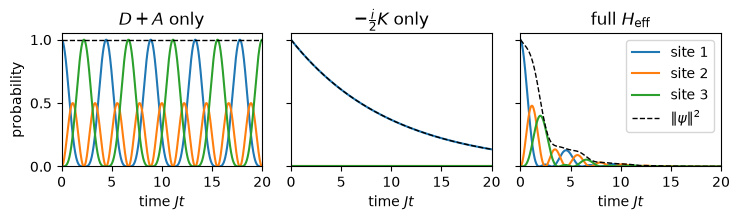

yield phi = 0.7343


In [4]:
# initial state: one excitation on site `start`
psi0 = np.eye(3, dtype=complex)[start - 1]

# time steps
t = np.linspace(0, 100, 5001)

# function to evolve the state psi(t) = exp(-i Hc t) psi0 for a given Hamiltonian Hc
def evolve(Hc):
    U = expm(-1j * Hc * t[1])                 # one time step
    psi = [psi0]
    for _ in t[1:]:
        psi.append(U @ psi[-1])
    return np.array(psi)                      # rows: times, columns: sites

# plot the evolution of the state for different Hamiltonians
fig, axs = plt.subplots(1, 3, figsize=(7.5, 2.3), sharey=True)
for ax, Hc, title in zip(axs, [H, -0.5j * K, H_eff], [r"$D+A$ only", r"$-\frac{i}{2}K$ only", r"full $H_{\rm eff}$"]):
    p = np.abs(evolve(Hc)) ** 2
    ax.plot(t, p, label=["site 1", "site 2", "site 3"])
    ax.plot(t, p.sum(1), "k--", lw=1, label=r"$\|\psi\|^2$")
    ax.set(title=title, xlim=(0, 20), ylim=(0, 1.05), xlabel=r"time $Jt$")
# label
axs[0].set_ylabel("probability"); axs[2].legend()
plt.tight_layout() 
plt.show();

# evaluate and print the yield
phi = Gx * np.trapezoid(np.abs(evolve(H_eff)[:, sink - 1]) ** 2, t)
print(f"yield phi = {phi:.4f}")

Only the anti-Hermitian part changes the norm, $d\|\psi\|^2/dt=-\psi^\dagger K\psi\le0$. 

With $D+A$ alone the excitation hops back and forth forever. 

With $-\tfrac{i}{2}K$ alone it never leaves site 1. 

Current needs both: $A$ brings the excitation to site 3 and the arrow takes it out.

## 3. The spectrum

The eigenvalues of $H_{\rm eff}$ are complex: 

$$\mu_k=E_k-i\gamma_k/2$$

where $E_k$ is the energy and $\gamma_k$ the decay rate of mode $k$. 

Because $H_{\rm eff}$ is not Hermitian, each mode has a right eigenvector $r_k$ (where the mode lives) and a left eigenvector $l_k$ (how strongly each initial site excites it), normalised so that $l_kr_k=1$. 

Energy on site 1 reaches site 3 through mode $k$ with amplitude $a_k=(r_k)_3(l_k)_1$, so $\psi_3(t)=\sum_ka_ke^{-i\mu_kt}$. 

The time integral then gives:

$$\phi=\Gamma_x\sum_{k,l}\frac{a_k\,a_l^*}{i\,(\mu_k-\mu_l^*)}.$$

The terms with $k\ne l$ are interference between the pathways $1\to k\to3$ and cannot be dropped.

In [5]:
def spectrum(Gx):
    # eignenvalues and left/right eigenvectors of H_eff
    mu, l, r = eig(make_H_eff(Gx), left=True)
    # normalize the left eigenvectors so that l_k r_k = 1
    l = l.conj() / np.sum(l.conj() * r, 0)       
    # compute the yield from the spectrum
    a = r[sink - 1] * l[start - 1]             
    phi = Gx * np.sum(np.outer(a, a.conj()) / (1j * (mu[:, None] - mu.conj()[None, :]))).real
    # return the eigenvalues and the yield from the spectrum
    return mu, phi

# compute the spectrum and the yield from the spectrum
mu, phi_spec = spectrum(Gx)
print("mu_k =", np.round(np.sort_complex(mu), 3))
print(f"yield from the spectrum = {phi_spec:.4f}, from the time integral = {phi:.4f}")

mu_k = [-1.387-0.171j  0.   -0.308j  1.387-0.171j]
yield from the spectrum = 0.7343, from the time integral = 0.7343


### How strong should the extraction be? 

We vary $\Gamma_x$ and follow the yield (left) and the decay rates of the three modes (right). 

The line is the time integral, the open markers the spectral formula.

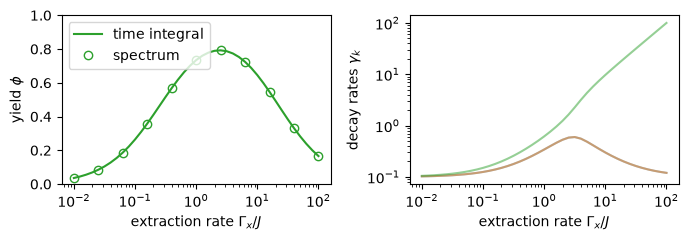

In [6]:
Gxs = np.logspace(-2, 2, 41)
phi_t = [G * np.trapezoid(np.abs(evolve(make_H_eff(G))[:, sink - 1]) ** 2, t) for G in Gxs]
phi_s = [spectrum(G)[1] for G in Gxs]
rates = [np.sort(-2 * spectrum(G)[0].imag) for G in Gxs]

fig, axs = plt.subplots(1, 2, figsize=(7, 2.5))

# plot the yield from the time integral and from the spectrum
axs[0].semilogx(Gxs, phi_t, color="#2ca02c", label="time integral")
axs[0].semilogx(Gxs[::4], phi_s[::4], "o", mfc="none", color="#2ca02c", label="spectrum")
axs[0].set(xlabel=r"extraction rate $\Gamma_x/J$", ylabel=r"yield $\phi$", ylim=(0, 1))
axs[0].legend(loc="upper left")

# plot the decay rates of the three modes 
for rate in np.array(rates).T:
    axs[1].loglog(Gxs, rate, alpha = 0.5)
axs[1].set(xlabel=r"extraction rate $\Gamma_x/J$", ylabel=r"decay rates $\gamma_k$")
plt.tight_layout(); plt.show()

The yield peaks near $\Gamma_x\approx2.5\,J$.

* **Weak extraction.** All modes decay at about $\gamma$, so the excitation is mostly emitted before it is extracted.
* **Strong extraction.** One mode localises on site 3 and decays at about $\Gamma_x$, but an excitation starting on site 1 hardly excites it. The other two modes live on sites 1 and 2 and decay ever more slowly, because a fast loss on site 3 blocks hopping into it (the quantum Zeno effect). Emission wins again.

## 4. Take-home

* Site energies and undirected edges give the Hermitian part $D+A$, which sets the mode energies $E_k$.
* Arrows out give the anti-Hermitian part $-\tfrac{i}{2}K$, which sets the decay rates $\gamma_k$ and is the only part that removes probability.
* The initial site selects modes through the left eigenvectors, the extraction site through the right eigenvectors.
* The yield is a sum over interfering pathways $1\to k\to3$.